# TP3 — Big data : recommander des films Netflix avec Spark (100 millions de notes)

*Cycle Big Data **Spark (Data → EDA → Prétraitement) → Transformation → ML → Éval → Déploiement**, à partir du
notebook Kaggle [Netflix - Movie recommendation](https://www.kaggle.com/code/laowingkin/netflix-movie-recommendation)
(DLao / laowingkin), sur le jeu [Netflix Prize data](https://www.kaggle.com/datasets/netflix-inc/netflix-prize-data)
(100 480 507 notes, 480 189 abonnés, 17 770 films).*

Enzo Caramella — identifiant 24021136 — novembre 2026

## Ma contribution

### Le notebook est-il correct ?

**Oui.** Il s'exécute de bout en bout (*Restart & Run All*) en 17 minutes environ, sous Windows 11 avec Python 3.12,
PySpark 4.2 (Java 21), 4 threads et 3 Go de mémoire pour le driver Spark. Les données sont incluses dans
`netflix_prize_dataset/`, et les dépendances sont listées dans `requirements.txt`.

### Pourquoi ce notebook de départ ?

C'est le notebook **le plus voté** de l'onglet *Code* du jeu de données (environ 3 400 votes). Il est bien structuré :
chargement du format brut, exploration, réduction des données, modèle SVD, recommandations pour un utilisateur et
films similaires. Surtout, il illustre exactement le problème du Big Data : l'auteur ne charge **qu'un des quatre
fichiers** « pour gagner du temps », et doit retirer des données parce que son noyau manque de mémoire. C'est le
point de départ idéal pour montrer ce que Spark change.

### Problèmes rencontrés dans le notebook d'origine

1. **Il ne passe pas à l'échelle** : il est écrit en pandas, numpy et *surprise*, des outils qui ne fonctionnent que
   sur une seule machine. Il n'utilise que 24 millions des 100 millions de notes, et la matrice pivot dense
   utilisateurs × films, qui sert à la corrélation de Pearson, ne tient en mémoire que sur un petit échantillon.
2. **Format brut atypique** : l'identifiant du film n'apparaît qu'une fois, en en-tête de son bloc de notes. L'auteur
   le reconstruit avec une boucle Python qui recopie un tableau numpy à chaque film (`np.append`), une méthode qui ne
   tiendrait pas sur les 17 770 films.
3. **Évaluation incomplète** : la SVD est évaluée par validation croisée, puis réentraînée sur toutes les données avant de
   recommander. Il n'y a ni jeu de test séparé pour le modèle final, ni référence simple à laquelle comparer son RMSE.
4. **Taille des données** : les fichiers bruts font 2 Go, alors que GitHub refuse les fichiers de plus de 100 Mo.
5. **Mémoire de la machine** : une première exécution, avec 8 threads et 6 Go pour Spark, a été interrompue, car la
   mémoire libre du portable était tombée sous 3 Go.
6. **Windows** : la sauvegarde native d'un modèle Spark (`model.save`) exige `winutils.exe`, absent de la machine.

### Modifications apportées

Les étapes reprises du notebook d'origine sont signalées par **(origine)**.

* **Tout le cycle amont passe par Spark**, sur les 100 millions de notes : lecture du texte brut, rattachement des
  notes à leur film avec une fenêtre `last(..., ignorenulls=True)`, EDA en agrégations Spark, contrôles qualité,
  puis filtrage au 70e centile, la règle de l'auteur appliquée cette fois à l'ensemble.
* **Données** : les 4 fichiers sont recompressés en **7 morceaux `.txt.gz`** de moins de 100 Mo, coupés juste avant un
  en-tête de film. Spark les lit directement.
* **Modèle** : la SVD de *surprise* est remplacée par **ALS** de Spark MLlib (factorisation de matrice distribuée), et la
  corrélation de Pearson par la **similarité cosinus** entre vecteurs de films. Les hyperparamètres sont choisis sur un
  jeu de validation, et l'évaluation finale porte sur un test séparé, avec deux références (moyenne et biais).
* **Mémoire** : 4 threads, 3 Go pour le driver, et les tables de 100 millions de lignes mises en cache sur disque. Ces
  valeurs se règlent par les variables `TP3_SPARK_MASTER` et `TP3_SPARK_MEMORY`.
* **Déploiement** : les facteurs ALS sont exportés en numpy (au lieu de `model.save`), avec les titres, la configuration
  et les métriques. Une fonction de recommandation, **sans Spark**, les recharge et sert un CSV d'utilisateurs, avec un
  repli sur les films populaires pour les inconnus. Elle retrouve exactement le même top 10 que Spark.

### Autres informations

* Résultat principal : **RMSE = 0,841** sur 1,7 million de notes de test, contre 0,912 pour le modèle de biais et 1,061
  pour la moyenne. Pour référence, *Cinematch*, le système de Netflix à l'époque, obtenait 0,951 sur un test plus
  difficile.
* Simplification assumée : comme dans le notebook d'origine, ALS n'apprend que sur les films du premier fichier, soit
  17,3 millions de notes après filtrage. Les étapes Data, EDA et Prétraitement portent, elles, sur les 100 millions de
  notes.
* Le dossier `artefacts/` contient tout ce que le notebook produit : facteurs du modèle, titres, configuration,
  métriques, graphiques, exemple d'entrée et recommandations.

## Sommaire

Cycle Big Data : **Spark (Data → EDA → Prétraitement) → Transformation → ML → Éval → Déploiement**

1. [Configuration] Session Spark
2. [Data] Lecture et analyse des 100 millions de notes brutes avec Spark
3. [EDA] Distribution des notes, activité des utilisateurs, longue traîne des films
4. [Prétraitement] Contrôles qualité et filtrage des films et utilisateurs peu actifs
5. [Transformation] Périmètre d'apprentissage, découpage apprentissage / validation / test
6. [ML] Références (moyenne, biais) et factorisation de matrice ALS
7. [Éval] RMSE, erreurs par profil, recommandations et films similaires
8. [Déploiement] Export du modèle, rechargement sans Spark et recommandations
9. [Conclusion]

**Notebook de départ** : [*Netflix - Movie recommendation*](https://www.kaggle.com/code/laowingkin/netflix-movie-recommendation)
(DLao / laowingkin, Kaggle, 3 400 votes). Il est écrit en **pandas** et avec la bibliothèque **surprise** (SVD), et ne
charge qu'un des quatre fichiers « pour gagner du temps », faute de mémoire. Ici, tout le cycle passe par **Spark** :
les 100 millions de notes sont lues, analysées et filtrées avec Spark, et le modèle est un **ALS** de Spark MLlib, la
version distribuée de la factorisation de matrice. Les étapes reprises du notebook d'origine sont signalées par
**(origine)**.

## [Configuration] Session Spark

Spark tourne en mode local avec **4 threads** et **3 Go** pour le driver. Le master `local[4,4]` signifie 4 tâches en
parallèle, avec jusqu'à 4 essais par tâche, car sous Windows une tâche peut échouer par intermittence (voir TP2). Tout
le notebook n'utilise que des opérations **exécutées dans la JVM** (DataFrames, Spark SQL, Spark MLlib), sans UDF
Python, pour rester rapide et stable.

> **Pourquoi si peu de ressources ?** Une première exécution, avec 8 threads et 6 Go, a été interrompue : pendant la
> lecture des 100 millions de notes, la mémoire libre de la machine (16 Go, partagés avec le système et d'autres
> applications) est tombée sous 3 Go. Avec moins de threads et un driver plus petit, Spark **déborde sur disque** : les
> tables de 100 millions de lignes sont mises en cache sur disque (`DISK_ONLY`), et les tris de la fenêtre et des
> agrégations s'écrivent en fichiers temporaires. C'est plus lent, mais la mémoire reste maîtrisée. C'est exactement ce
> qui permet à Spark de traiter des données plus grosses que la RAM. Les variables d'environnement `TP3_SPARK_MASTER`
> et `TP3_SPARK_MEMORY` permettent d'augmenter ces valeurs sur une machine mieux dotée. Avec ces réglages, le
> notebook complet s'exécute en **17 minutes environ**, et la mémoire libre de la machine n'est jamais descendue sous
> 5 Go.

In [1]:
import os, sys, glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F, Window
from pyspark import StorageLevel
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

DONNEES = "netflix_prize_dataset"
ARTEFACTS = "artefacts"
os.makedirs(ARTEFACTS, exist_ok=True)
GRAINE = 42
T0 = time.perf_counter()

spark = (SparkSession.builder.master(os.environ.get("TP3_SPARK_MASTER", "local[4,4]"))
         .appName("TP3 big - Netflix Prize")
         .config("spark.driver.memory", os.environ.get("TP3_SPARK_MEMORY", "3g"))
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| master", spark.sparkContext.master, "|", spark.sparkContext.defaultParallelism, "threads")

BLEU, BLEU_CLAIR, ORANGE, GRIS, ENCRE_2 = "#2a78d6", "#86b6ef", "#eb6834", "#8a8984", "#52514e"
def chrono(t):
    return f"{time.perf_counter() - t:.1f} s"

Spark 4.2.0 | master local[4,4] | 4 threads


## [Data] Lecture et analyse des notes brutes avec Spark

**Jeu de données** : [*Netflix Prize data*](https://www.kaggle.com/datasets/netflix-inc/netflix-prize-data), publié par
Netflix en 2006 pour son concours à un million de dollars. Il contient **100 480 507 notes** (1 à 5 étoiles) données
par **480 189 abonnés** anonymes à **17 770 films**, entre 1998 et 2005.

**Format brut** : les quatre fichiers `combined_data_*.txt` (2 Go) ne sont pas des CSV ordinaires. L'identifiant du
film est écrit **une seule fois**, sur sa propre ligne, et toutes les notes qui suivent lui appartiennent :

```
1:
1488844,3,2005-09-06
822109,5,2005-05-13
...
2:
2059652,4,2005-09-05
```

Pour tenir sous la limite de 100 Mo de GitHub, les fichiers sont fournis compressés en **7 morceaux `.txt.gz`** (84 à 96 Mo), coupés
juste avant une ligne `ID_film:`. Spark lit le gzip directement, sans décompression préalable. Chaque morceau est lu
par une seule tâche, car un fichier gzip ne se découpe pas. Cela donne 7 tâches, dont 4 tournent en même temps ici.

In [2]:
fichiers = sorted(glob.glob(os.path.join(DONNEES, "combined_data_part*.txt.gz")))
print(f"{len(fichiers)} morceaux, {sum(os.path.getsize(f) for f in fichiers) / 1e6:.0f} Mo compressés")
brut = spark.read.text(fichiers)
brut.show(4, truncate=False)

7 morceaux, 656 Mo compressés


+--------------------+
|value               |
+--------------------+
|7725:               |
|1342774,1,2000-02-03|
|978348,3,2001-09-07 |
|2602019,3,2004-12-25|
+--------------------+
only showing top 4 rows


**Rattacher chaque note à son film.** Le notebook d'origine charge tout dans pandas, repère les lignes d'en-tête
(`Rating` vide), puis construit à la main un tableau numpy d'identifiants de film. L'auteur note que la boucle naïve
épuisait la mémoire. Avec Spark, la même idée s'exprime en trois opérations distribuées :

1. numéroter les lignes **dans l'ordre de lecture** de chaque fichier (`monotonically_increasing_id`, croissant dans
   une partition) ;
2. extraire l'identifiant sur les lignes d'en-tête (`1:` → 1), `NULL` ailleurs ;
3. propager le dernier identifiant non nul vers le bas, **par fichier** : `last(..., ignorenulls=True)` sur une
   fenêtre ordonnée. Comme chaque morceau commence par un en-tête, aucune note ne peut rester sans film.

Les 100 millions de lignes sont lues, rattachées à leur film et typées en **3 minutes et demie** environ. Le résultat
est mis en cache sur disque, pour que les étapes suivantes ne relisent pas le texte brut.

In [3]:
t = time.perf_counter()
est_entete = F.col("value").endswith(":")
fenetre = Window.partitionBy("fichier").orderBy("pos").rowsBetween(Window.unboundedPreceding, Window.currentRow)
champs = F.split(F.col("value"), ",")
notes = (brut
         .withColumn("fichier", F.input_file_name())
         .withColumn("pos", F.monotonically_increasing_id())
         .withColumn("movie_id", F.when(est_entete, F.regexp_replace("value", ":", "").cast("int")))
         .withColumn("movie_id", F.last("movie_id", ignorenulls=True).over(fenetre))
         .filter(~est_entete)
         .select("movie_id",
                 champs[0].cast("int").alias("cust_id"),
                 champs[1].cast("tinyint").alias("rating"),
                 F.to_date(champs[2]).alias("date"))
         .persist(StorageLevel.DISK_ONLY))
n_notes = notes.count()
print(f"{n_notes:,} notes lues et analysées en {chrono(t)}".replace(",", " "))
notes.show(5)
notes.printSchema()

100 480 507 notes lues et analysées en 215.6 s


+--------+-------+------+----------+
|movie_id|cust_id|rating|      date|
+--------+-------+------+----------+
|   13196| 577397|     2|2004-01-14|
|   13196|1744889|     1|2004-03-03|
|   13196|1319997|     2|2003-12-17|
|   13196| 160876|     3|2005-08-26|
|   13196|1608985|     3|2005-09-05|
+--------+-------+------+----------+
only showing top 5 rows
root
 |-- movie_id: integer (nullable = true)
 |-- cust_id: integer (nullable = true)
 |-- rating: byte (nullable = true)
 |-- date: date (nullable = true)



**Titres des films.** `movie_titles.csv` n'est pas un CSV standard non plus : il est encodé en Latin-1 et certains
titres contiennent des virgules non protégées (`Lord of the Rings: The Return of the King, The`). On lit donc chaque
ligne comme du texte, et on la découpe avec une expression régulière : identifiant, année, puis **tout le reste** pour
le titre.

In [4]:
titres = (spark.read.option("encoding", "ISO-8859-1").text(os.path.join(DONNEES, "movie_titles.csv"))
          .select(F.regexp_extract("value", r"^(\d+),([^,]*),(.*)$", 1).cast("int").alias("movie_id"),
                  F.expr(r"try_cast(regexp_extract(value, '^(\\d+),([^,]*),(.*)$', 2) AS INT)").alias("year"),
                  F.regexp_extract("value", r"^(\d+),([^,]*),(.*)$", 3).alias("title"))
          .cache())
print(titres.count(), "films")
titres.filter(F.col("title").contains(",")).show(3, truncate=False)

17770 films


+--------+----+-------------------------------------------------+
|movie_id|year|title                                            |
+--------+----+-------------------------------------------------+
|72      |1974|At Home Among Strangers, A Stranger Among His Own|
|264     |2002|Angelina Ballerina: Lights, Camera, Action!      |
|350     |1993|Dr. Quinn, Medicine Woman: Season 3              |
+--------+----+-------------------------------------------------+
only showing top 3 rows


## [EDA] Distribution des notes, activité des utilisateurs, longue traîne des films

Toutes les agrégations sont calculées par Spark sur les 100 millions de lignes. Seuls les **petits résultats
agrégés** passent par pandas pour les graphiques.

**(origine)** Le notebook d'origine commence par la répartition des notes et les volumes (films, clients, notes), mais
seulement sur le premier fichier (24 millions de notes). Ici, ils sont calculés sur l'ensemble :

In [5]:
t = time.perf_counter()
volumes = notes.agg(F.countDistinct("movie_id").alias("films"), F.countDistinct("cust_id").alias("utilisateurs"),
                    F.min("date").alias("premiere_note"), F.max("date").alias("derniere_note"),
                    F.round(F.avg("rating"), 3).alias("note_moyenne")).first().asDict()
volumes["notes"] = n_notes
volumes["densite_matrice_%"] = round(100 * n_notes / (volumes["films"] * volumes["utilisateurs"]), 2)
print(f"(calcul en {chrono(t)})")
pd.Series(volumes).to_frame("valeur")

(calcul en 17.4 s)


,valeur
films,17770
utilisateurs,480189
premiere_note,1999-11-11
derniere_note,2005-12-31
note_moyenne,3.604
notes,100480507
densite_matrice_%,1.18


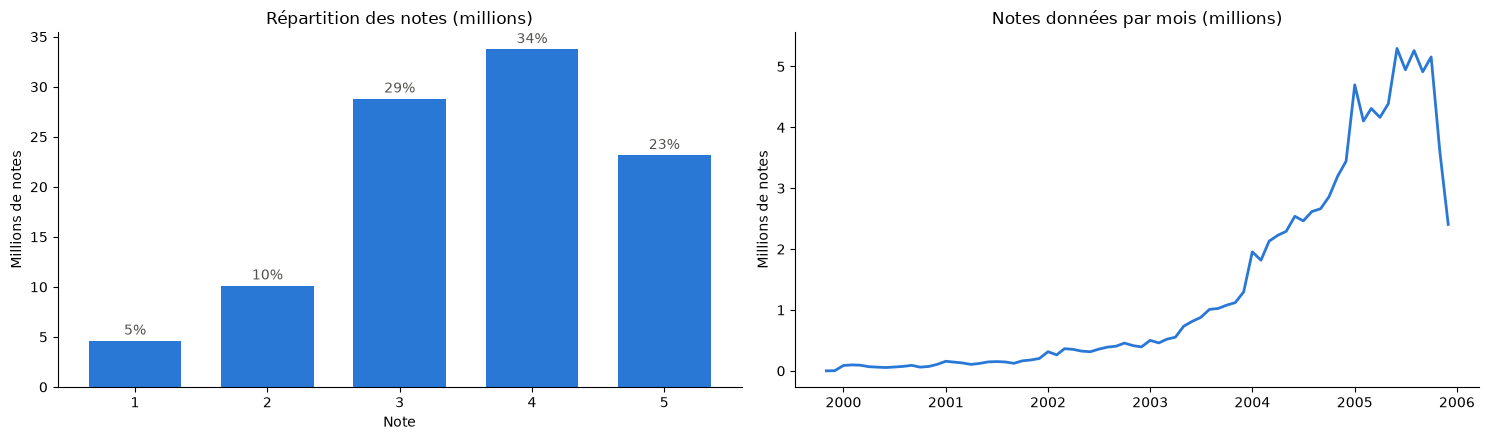

In [6]:
par_note = notes.groupBy("rating").count().orderBy("rating").toPandas()
par_mois = (notes.groupBy(F.date_trunc("month", "date").alias("mois")).count().orderBy("mois").toPandas())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
b = axes[0].bar(par_note.rating.astype(str), par_note["count"] / 1e6, color=BLEU, width=0.7)
axes[0].bar_label(b, labels=[f"{p:.0%}" for p in par_note["count"] / n_notes], color=ENCRE_2, padding=2)
axes[0].set(title="Répartition des notes (millions)", xlabel="Note", ylabel="Millions de notes")
axes[1].plot(par_mois.mois, par_mois["count"] / 1e6, color=BLEU, lw=2)
axes[1].set(title="Notes données par mois (millions)", ylabel="Millions de notes")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(ARTEFACTS, "eda.png"), dpi=110); plt.show()

* **(origine)** *« the rating tends to be relatively positive (>3) »* : c'est confirmé sur les 100 millions de notes.
  **57 %** sont des 4 ou des 5, contre 15 % de 1 ou 2, et la moyenne est de **3,60**. Comme le suppose l'auteur, les
  clients mécontents notent moins.
* L'activité **explose** à partir de 2004 : de moins de 0,5 million de notes par mois jusqu'en 2002, on passe à plus de
  5 millions mi-2005. Plus de la moitié des notes datent des 18 derniers mois.
* La chute de fin 2005 s'explique très probablement par le concours lui-même : Netflix a retiré les notes les plus
  récentes de chaque utilisateur pour constituer son jeu de test secret (*qualifying set*), absent de ces fichiers.
* La matrice utilisateurs × films n'est remplie qu'à **1,2 %** : 98,8 % des couples n'ont pas de note. C'est tout l'enjeu
  d'un système de recommandation, qui doit **deviner** ces cases vides.

,10 %,25 %,50 %,75 %,90 %,99 %
notes par film,117,191,559,2647,12136,90675
notes par utilisateur,19,39,96,258,537,1355


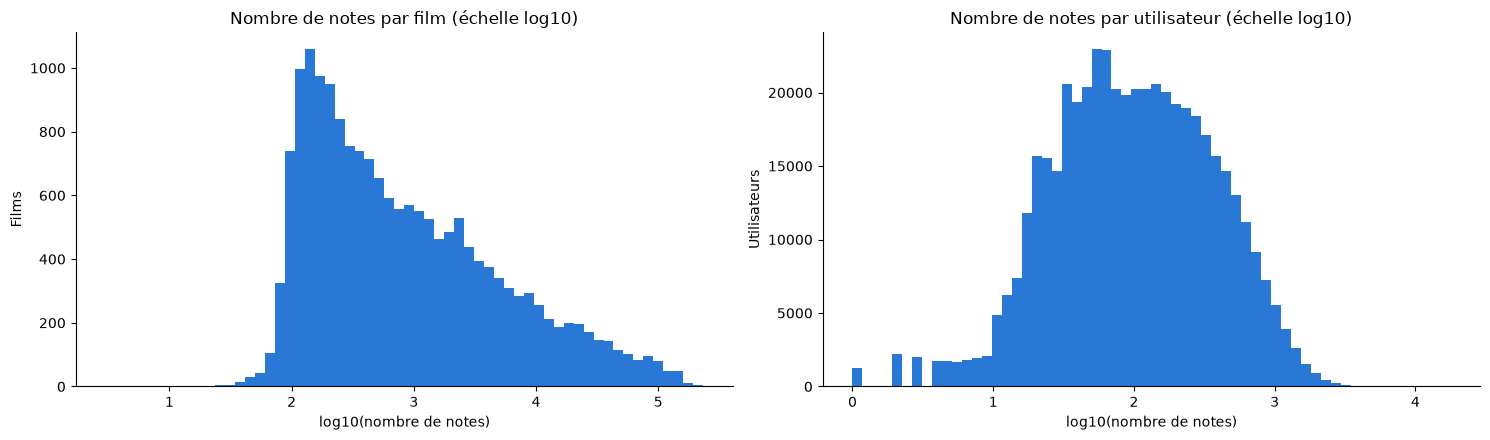

In [7]:
par_film = notes.groupBy("movie_id").agg(F.count("*").alias("n"), F.avg("rating").alias("moyenne")).cache()
par_client = notes.groupBy("cust_id").agg(F.count("*").alias("n"), F.avg("rating").alias("moyenne")).cache()

def quantiles(df, nom):
    q = df.approxQuantile("n", [0.1, 0.25, 0.5, 0.75, 0.9, 0.99], 0.001)
    return pd.Series(q, index=["10 %", "25 %", "50 %", "75 %", "90 %", "99 %"], name=nom).astype(int)

display(pd.concat([quantiles(par_film, "notes par film"), quantiles(par_client, "notes par utilisateur")], axis=1).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, df, nom in [(axes[0], par_film, "film"), (axes[1], par_client, "utilisateur")]:
    n = np.log10(df.select("n").toPandas()["n"])
    ax.hist(n, bins=60, color=BLEU)
    ax.set(title=f"Nombre de notes par {nom} (échelle log10)", xlabel="log10(nombre de notes)", ylabel=f"{nom.capitalize()}s")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

**Longue traîne.** La moitié des films ont moins de **560 notes**, alors que 10 % en ont plus de 12 000 et que trois
dépassent 200 000 (*Miss Congeniality*, *Independence Day*, *The Patriot*). Côté utilisateurs, la médiane est de
**96 notes**, mais 1 % en ont donné plus de 1 350. Un modèle aura beaucoup d'informations sur les films populaires et
les gros utilisateurs, et très peu sur les autres.

Les films les mieux notés sont les éditions longues du *Seigneur des anneaux* (4,7 sur 5) et des **saisons de séries**
(*Les Simpson*, *Les Soprano*, *Family Guy*). Les séries sont regardées surtout par leurs fans, qui les notent très
bien : on retrouvera ce biais dans les recommandations.

In [8]:
top = (par_film.join(titres, "movie_id").orderBy(F.desc("n"))
       .select("title", "year", "n", F.round("moyenne", 2).alias("moyenne")).limit(10).toPandas())
mieux_notes = (par_film.filter("n >= 10000").join(titres, "movie_id").orderBy(F.desc("moyenne"))
               .select("title", "year", "n", F.round("moyenne", 2).alias("moyenne")).limit(10).toPandas())
print("Films les plus notés :"); display(top)
print("Films les mieux notés (au moins 10 000 notes) :"); display(mieux_notes)

Films les plus notés :


,title,year,n,moyenne
0,Miss Congeniality,2000,232944,3.36
1,Independence Day,1996,216596,3.72
2,The Patriot,2000,200832,3.78
3,The Day After Tomorrow,2004,196397,3.44
4,Pirates of the Caribbean: The Curse of the Bla...,2003,193941,4.15
5,Pretty Woman,1990,193295,3.91
6,Forrest Gump,1994,181508,4.30
7,The Green Mile,1999,181426,4.31
8,Con Air,1997,178068,3.45
9,Twister,1996,177556,3.41


Films les mieux notés (au moins 10 000 notes) :


,title,year,n,moyenne
0,Lord of the Rings: The Return of the King: Ext...,2003,73335,4.72
1,The Lord of the Rings: The Fellowship of the R...,2001,73422,4.72
2,Lord of the Rings: The Two Towers: Extended Ed...,2002,74912,4.70
3,The Shawshank Redemption: Special Edition,1994,139660,4.59
4,Lord of the Rings: The Return of the King,2003,134284,4.55
5,Star Wars: Episode V: The Empire Strikes Back,1980,92470,4.54
6,The Simpsons: Season 5,1993,17292,4.54
7,The Sopranos: Season 5,2004,21043,4.53
8,Family Guy: Vol. 2: Season 3,2001,21385,4.53
9,The Simpsons: Season 4,1992,18413,4.52


## [Prétraitement] Contrôles qualité et filtrage

### Contrôles qualité

On vérifie les valeurs manquantes, le domaine des notes, et l'absence de **doublons** (un même utilisateur qui
noterait deux fois le même film).

In [9]:
t = time.perf_counter()
controles = notes.agg(
    F.sum(F.col("movie_id").isNull().cast("int")).alias("film_manquant"),
    F.sum(F.col("cust_id").isNull().cast("int")).alias("utilisateur_manquant"),
    F.sum(F.col("date").isNull().cast("int")).alias("date_manquante"),
    F.sum((~F.col("rating").between(1, 5)).cast("int")).alias("note_hors_1_5"),
).first().asDict()
controles["doublons_utilisateur_film"] = n_notes - notes.select("cust_id", "movie_id").distinct().count()
print(f"(contrôles en {chrono(t)})")
pd.Series(controles).to_frame("lignes")

(contrôles en 111.9 s)


,lignes
film_manquant,0
utilisateur_manquant,0
date_manquante,0
note_hors_1_5,0
doublons_utilisateur_film,0


Les données sont **propres** : aucune valeur manquante, aucune note hors de 1 à 5, aucun doublon. Le rattachement
des notes aux films est donc correct sur l'ensemble des 100 millions de lignes.

### Filtrage des films et des utilisateurs peu actifs

**(origine)** *Data slicing* : l'auteur retire les films et les utilisateurs **les moins actifs**, sous le
70e centile du nombre de notes. Son but est à la fois de réduire le volume, sans quoi son noyau manque de mémoire, et
d'améliorer la qualité : peu de notes signifie un signal peu fiable. Je reprends exactement cette règle, mais
calculée par Spark sur les 100 millions de notes.

In [10]:
t = time.perf_counter()
seuil_film = round(par_film.approxQuantile("n", [0.7], 0.0001)[0])
seuil_client = round(par_client.approxQuantile("n", [0.7], 0.0001)[0])
print(f"Seuil films : au moins {seuil_film} notes | seuil utilisateurs : au moins {seuil_client} notes")

films_gardes = par_film.filter(F.col("n") >= seuil_film).select("movie_id")
clients_gardes = par_client.filter(F.col("n") >= seuil_client).select("cust_id")
filtrees = (notes.join(F.broadcast(films_gardes), "movie_id").join(clients_gardes, "cust_id")
            .persist(StorageLevel.DISK_ONLY))
n_filtrees = filtrees.count()
resume = pd.DataFrame({
    "avant": [n_notes, volumes["films"], volumes["utilisateurs"]],
    "après": [n_filtrees, films_gardes.count(), clients_gardes.count()],
}, index=["notes", "films", "utilisateurs"])
resume["conservé"] = (resume["après"] / resume["avant"]).map("{:.0%}".format)
print(f"(filtrage en {chrono(t)})")
resume

Seuil films : au moins 1947 notes | seuil utilisateurs : au moins 211 notes


(filtrage en 24.0 s)


,avant,après,conservé
notes,100480507,71836911,71%
films,17770,5334,30%
utilisateurs,480189,144380,30%


Les seuils sont de **1 947 notes** par film et **211 notes** par utilisateur. On ne garde que **30 % des films** et
**30 % des utilisateurs**, mais ils concentrent encore **71 % des notes** (71,8 millions) : c'est la longue traîne vue
dans l'EDA. Le notebook d'origine calculait ces centiles sur son seul premier fichier ; ici, ils portent sur
l'ensemble. Les films et utilisateurs retirés pourront toujours recevoir une recommandation « par
défaut » (les films les mieux notés), mais le modèle collaboratif ne les connaîtra pas : c'est le problème du
**démarrage à froid**.

## [Transformation] Périmètre d'apprentissage et découpage

**Périmètre.** Pour la modélisation, je reprends le périmètre du notebook d'origine : le **premier fichier**
(films 1 à 4 499) après filtrage. La comparaison avec son approche reste ainsi directe, et l'apprentissage ALS tient
en quelques minutes sur un portable. Tout le cycle amont (Data, EDA, Prétraitement) a été fait sur les **100 millions**
de notes. Le même code s'appliquerait au jeu filtré complet, sur un cluster, en changeant la seule ligne du filtre.

**Découpage** : 80 % apprentissage, 10 % validation (choix des hyperparamètres), 10 % test (évaluation finale), tirés
au hasard parmi les notes.

In [11]:
t = time.perf_counter()
perimetre = filtrees.filter(F.col("movie_id") <= 4499).select("cust_id", "movie_id", F.col("rating").cast("float").alias("rating"))
app, val, test = perimetre.randomSplit([0.8, 0.1, 0.1], seed=GRAINE)
app = app.persist(StorageLevel.MEMORY_AND_DISK); val = val.cache(); test = test.cache()
n_app, n_val, n_test = app.count(), val.count(), test.count()
print(f"Périmètre : {n_app + n_val + n_test:,} notes | apprentissage {n_app:,} | validation {n_val:,} | test {n_test:,}".replace(",", " "))
print(f"Utilisateurs : {perimetre.select('cust_id').distinct().count():,} | films : {perimetre.select('movie_id').distinct().count():,}".replace(",", " "))
print(f"(découpage en {chrono(t)})")

Périmètre : 17 284 230 notes | apprentissage 13 825 839 | validation 1 729 093 | test 1 729 298


Utilisateurs : 144 380 | films : 1 307
(découpage en 36.6 s)


Le périmètre compte **17,3 millions de notes**, données par 144 380 utilisateurs à **1 307 films** : seuls 1 307 des
4 499 films du premier fichier passent le seuil de 1 947 notes. Chaque utilisateur retenu a noté au moins un de ces
films.

**Transformation pour ALS.** L'algorithme attend trois colonnes : un identifiant d'utilisateur entier, un identifiant
d'article entier et une note. Les identifiants Netflix sont déjà des entiers (inférieurs à 2,7 millions), il n'y a donc
pas besoin de ré-indexer. Pour le modèle de **biais**, on calcule en Spark la moyenne globale μ, puis l'écart moyen de
chaque film (b_i) et de chaque utilisateur (b_u), avec un terme de régularisation λ qui ramène vers 0 les écarts
estimés sur peu de notes.

In [12]:
mu = app.agg(F.avg("rating")).first()[0]
LAMBDA = 25.0
biais_film = (app.groupBy("movie_id").agg((F.sum(F.col("rating") - mu) / (F.count("*") + LAMBDA)).alias("b_i")))
biais_client = (app.join(biais_film, "movie_id").groupBy("cust_id")
                .agg((F.sum(F.col("rating") - mu - F.col("b_i")) / (F.count("*") + LAMBDA)).alias("b_u")))
biais_film, biais_client = biais_film.cache(), biais_client.cache()
print(f"μ = {mu:.4f} | {biais_film.count()} biais de films | {biais_client.count()} biais d'utilisateurs")

μ = 3.5919 | 1307 biais de films | 144380 biais d'utilisateurs


## [ML] Références et factorisation de matrice ALS

**(origine)** L'auteur utilise deux approches :

1. une **SVD** (bibliothèque *surprise*), qui factorise la matrice utilisateurs × films ;
2. la **corrélation de Pearson** entre colonnes de la matrice pivot (films), pour trouver les films similaires.

La SVD de *surprise* n'est pas distribuée, et la matrice pivot dense ne tiendrait pas en mémoire au-delà d'un
échantillon. L'équivalent distribué est **ALS** (*Alternating Least Squares*) de Spark MLlib. Chaque utilisateur u et
chaque film i y sont représentés par un vecteur de k facteurs latents, et la note prédite est leur produit scalaire.
ALS alterne deux problèmes de moindres carrés, résolus en parallèle sur les partitions : utilisateurs fixés, puis films
fixés. La similarité entre films se calcule ensuite directement sur les vecteurs de films (section Éval).

Pour juger ALS, on le compare d'abord à deux **références** :

* **Moyenne globale** : prédire μ pour tout le monde ;
* **Biais** : μ + b_u + b_i, qui capte que certains utilisateurs notent sévèrement et que certains films sont bons.

In [13]:
evaluateur = RegressionEvaluator(labelCol="rating", predictionCol="prediction", metricName="rmse")
evaluateur_mae = RegressionEvaluator(labelCol="rating", predictionCol="prediction", metricName="mae")

def predire_biais(df):
    return (df.join(biais_film, "movie_id", "left").join(biais_client, "cust_id", "left")
              .withColumn("prediction", F.least(F.lit(5.0), F.greatest(F.lit(1.0),
                          F.lit(mu) + F.coalesce("b_i", F.lit(0.0)) + F.coalesce("b_u", F.lit(0.0))))))

ref_val = {
    "Moyenne globale": evaluateur.evaluate(val.withColumn("prediction", F.lit(mu))),
    "Biais (μ + b_u + b_i)": evaluateur.evaluate(predire_biais(val)),
}
pd.Series(ref_val, name="RMSE validation").round(4).to_frame()

,RMSE validation
Moyenne globale,1.0616
Biais (μ + b_u + b_i),0.9128


**Choix des hyperparamètres d'ALS** sur le jeu de validation : rang k (nombre de facteurs) et régularisation λ.
Dix itérations par modèle, et `coldStartStrategy="drop"` pour ignorer, dans l'évaluation, les rares couples dont
l'utilisateur ou le film est absent de l'apprentissage.

In [14]:
grille = [(10, 0.05), (10, 0.1), (50, 0.05), (50, 0.1)]
essais = []
for rang, reg in grille:
    t = time.perf_counter()
    als = ALS(userCol="cust_id", itemCol="movie_id", ratingCol="rating", rank=rang, regParam=reg, maxIter=10,
              coldStartStrategy="drop", nonnegative=False, seed=GRAINE)
    m = als.fit(app)
    rmse = evaluateur.evaluate(m.transform(val))
    essais.append({"rang": rang, "regParam": reg, "RMSE validation": round(rmse, 4), "durée (s)": round(time.perf_counter() - t)})
    print(essais[-1])
essais = pd.DataFrame(essais).sort_values("RMSE validation")
meilleur_rang, meilleur_reg = int(essais.iloc[0]["rang"]), float(essais.iloc[0]["regParam"])
essais

{'rang': 10, 'regParam': 0.05, 'RMSE validation': 0.849, 'durée (s)': 36}


{'rang': 10, 'regParam': 0.1, 'RMSE validation': 0.8571, 'durée (s)': 31}


{'rang': 50, 'regParam': 0.05, 'RMSE validation': 0.8533, 'durée (s)': 199}


{'rang': 50, 'regParam': 0.1, 'RMSE validation': 0.8581, 'durée (s)': 199}


,rang,regParam,RMSE validation,durée (s)
0,10,0.05,0.8490,36
2,50,0.05,0.8533,199
1,10,0.10,0.8571,31
3,50,0.10,0.8581,199


Les deux références donnent déjà un repère : prédire la moyenne se trompe d'environ **1,06 étoile** (RMSE), et tenir
compte des biais d'utilisateur et de film descend à **0,91**. Sur la grille, le **rang 10 avec λ = 0,05** l'emporte
(RMSE de validation 0,849). Le rang 50 ne fait pas mieux (0,853) et coûte six fois plus de temps, car avec 17 millions
de notes, 50 facteurs par film et par utilisateur apprennent déjà du bruit.

**Modèle final** : les meilleurs hyperparamètres, réentraînés sur apprentissage + validation (90 % du périmètre), puis
évalués **une seule fois** sur le jeu de test.

In [15]:
t = time.perf_counter()
app_val = app.union(val).persist(StorageLevel.MEMORY_AND_DISK)
modele = ALS(userCol="cust_id", itemCol="movie_id", ratingCol="rating", rank=meilleur_rang, regParam=meilleur_reg,
             maxIter=15, coldStartStrategy="drop", seed=GRAINE).fit(app_val)
print(f"ALS final (rang {meilleur_rang}, λ {meilleur_reg}, 15 itérations) entraîné en {chrono(t)}")

ALS final (rang 10, λ 0.05, 15 itérations) entraîné en 54.1 s


## [Éval] RMSE, erreurs par profil, recommandations et films similaires

### Erreur de prédiction sur le jeu de test

In [16]:
pred_test = modele.transform(test).withColumn("prediction", F.least(F.lit(5.0), F.greatest(F.lit(1.0), "prediction"))).cache()
resultats = pd.DataFrame([
    {"modèle": "Moyenne globale", "RMSE": evaluateur.evaluate(test.withColumn("prediction", F.lit(mu))),
     "MAE": evaluateur_mae.evaluate(test.withColumn("prediction", F.lit(mu)))},
    {"modèle": "Biais (μ + b_u + b_i)", "RMSE": evaluateur.evaluate(predire_biais(test)), "MAE": evaluateur_mae.evaluate(predire_biais(test))},
    {"modèle": f"ALS (rang {meilleur_rang}, λ {meilleur_reg})", "RMSE": evaluateur.evaluate(pred_test), "MAE": evaluateur_mae.evaluate(pred_test)},
]).set_index("modèle").round(4)
resultats["gain RMSE vs moyenne"] = (1 - resultats["RMSE"] / resultats["RMSE"].iloc[0]).map("{:.1%}".format)
resultats

,RMSE,MAE,gain RMSE vs moyenne
modèle,,,
Moyenne globale,1.0611,0.8904,0.0%
Biais (μ + b_u + b_i),0.9121,0.7202,14.0%
"ALS (rang 10, λ 0.05)",0.8407,0.6609,20.8%


Sur 1,73 million de notes de test, ALS atteint un **RMSE de 0,841** et une **MAE de 0,66 étoile**. C'est 20,8 % de mieux
que la moyenne et 7,8 % de mieux que le modèle de biais : les facteurs latents captent bien des goûts que les biais
ignorent.

Pour situer ces chiffres : le système de Netflix de l'époque (*Cinematch*) avait un RMSE de **0,9514** sur le jeu de
test du concours, et l'équipe gagnante a atteint **0,8567** en 2009 avec un très grand ensemble de modèles. Notre
0,841 n'est **pas** meilleur que le leur : notre périmètre est plus facile (utilisateurs actifs, films populaires,
notes tirées au hasard plutôt que les plus récentes de chaque utilisateur). La comparaison n'est qu'indicative.

### Où le modèle se trompe-t-il ?

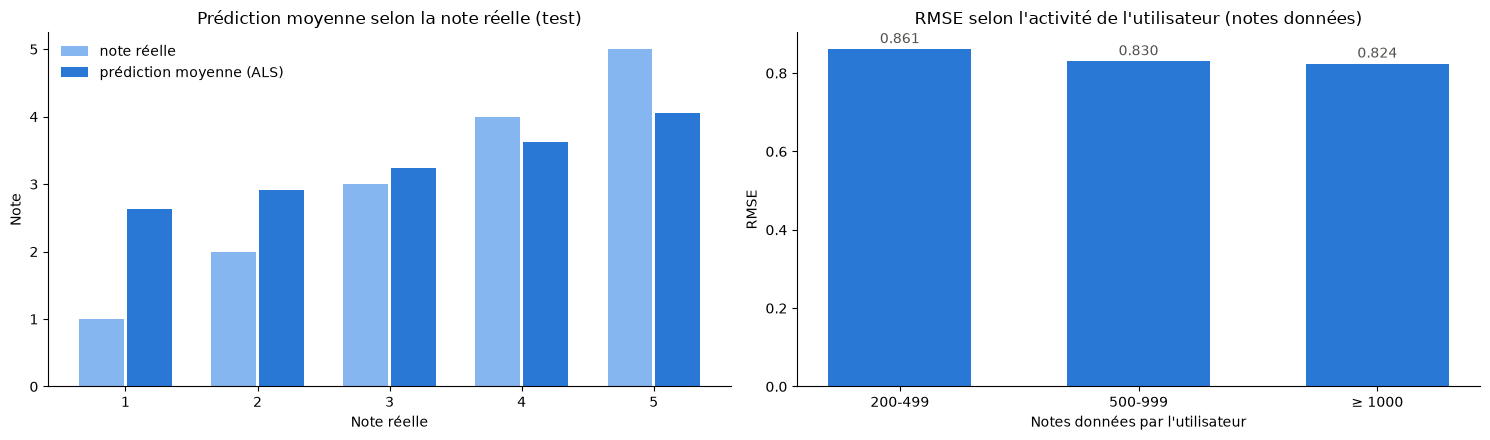

,rating,notes,prédiction moyenne,RMSE
0,1.0,71157,2.63,1.777
1,2.0,175128,2.91,1.066
2,3.0,518332,3.24,0.544
3,4.0,588646,3.63,0.596
4,5.0,376035,4.05,1.077


,tranche,notes,RMSE
0,b. 200-499,671928,0.861
1,c. 500-999,649059,0.830
2,d. ≥ 1000,408311,0.824


In [17]:
erreurs = pred_test.withColumn("erreur", F.col("prediction") - F.col("rating"))
par_vraie_note = (erreurs.groupBy("rating").agg(F.count("*").alias("notes"), F.round(F.avg("prediction"), 2).alias("prédiction moyenne"),
                  F.round(F.sqrt(F.avg(F.col("erreur") ** 2)), 3).alias("RMSE")).orderBy("rating").toPandas())
activite = erreurs.join(par_client.select("cust_id", F.col("n").alias("notes_utilisateur")), "cust_id")
tranches = (activite.withColumn("tranche", F.when(F.col("notes_utilisateur") < 200, "a. < 200")
                                .when(F.col("notes_utilisateur") < 500, "b. 200-499")
                                .when(F.col("notes_utilisateur") < 1000, "c. 500-999").otherwise("d. ≥ 1000"))
            .groupBy("tranche").agg(F.count("*").alias("notes"), F.round(F.sqrt(F.avg(F.col("erreur") ** 2)), 3).alias("RMSE"))
            .orderBy("tranche").toPandas())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = par_vraie_note.rating.astype(int)
axes[0].bar(x - 0.18, x, width=0.34, color=BLEU_CLAIR, label="note réelle")
axes[0].bar(x + 0.18, par_vraie_note["prédiction moyenne"], width=0.34, color=BLEU, label="prédiction moyenne (ALS)")
axes[0].set(title="Prédiction moyenne selon la note réelle (test)", xlabel="Note réelle", ylabel="Note")
axes[0].legend(frameon=False)
b = axes[1].bar(tranches.tranche.str[3:], tranches.RMSE, color=BLEU, width=0.6)
axes[1].bar_label(b, fmt="%.3f", color=ENCRE_2, padding=2)
axes[1].set(title="RMSE selon l'activité de l'utilisateur (notes données)", xlabel="Notes données par l'utilisateur", ylabel="RMSE")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(ARTEFACTS, "evaluation.png"), dpi=110); plt.show()
display(par_vraie_note, tranches)

* Comme tout modèle aux moindres carrés, ALS **tire vers la moyenne**. Il prédit en moyenne 2,63 pour un vrai 1 et
  4,05 pour un vrai 5, alors qu'il est précis sur les 3 et les 4 (RMSE de 0,54 et 0,60). Les mauvaises notes sont rares
  (14 % du test) et difficiles à anticiper : un utilisateur choisit en général des films qu'il pense aimer.
* L'erreur **diminue avec l'activité** de l'utilisateur, de 0,861 (200 à 499 notes) à 0,824 (1 000 notes et plus) :
  plus il a noté de films, mieux son vecteur de goûts est estimé. Aucun utilisateur n'a moins de 200 notes, car le
  filtrage n'a gardé que ceux qui en avaient au moins 211. Les utilisateurs occasionnels, plus difficiles, sont exclus
  du périmètre.

### Recommandations pour un utilisateur

**(origine)** Le notebook d'origine affiche les films notés 5 par l'utilisateur **785314**, puis ses 10 meilleures
recommandations. Je reprends le même utilisateur, avec ALS :

In [18]:
UTILISATEUR = 785314
aimes = (perimetre.filter((F.col("cust_id") == UTILISATEUR) & (F.col("rating") == 5)).join(titres, "movie_id")
         .select("title", "year").orderBy("year").toPandas())
print(f"Films notés 5 par l'utilisateur {UTILISATEUR} ({len(aimes)}) :")
display(aimes.head(15))

deja_vus = perimetre.filter(F.col("cust_id") == UTILISATEUR).select("movie_id")
candidats = perimetre.select("movie_id").distinct().join(deja_vus, "movie_id", "left_anti").withColumn("cust_id", F.lit(UTILISATEUR))
recos = (modele.transform(candidats).join(titres, "movie_id").orderBy(F.desc("prediction"))
         .select("title", "year", F.round("prediction", 2).alias("note_prédite")).limit(10).toPandas())
print(f"Top 10 des recommandations ALS pour l'utilisateur {UTILISATEUR} (films non encore notés) :")
recos

Films notés 5 par l'utilisateur 785314 (44) :


,title,year
0,The Mark of Zorro,1920
1,Animal Crackers,1930
2,The Maltese Falcon,1941
3,To Have and Have Not,1944
4,Kind Hearts and Coronets,1949
5,Singin' in the Rain,1952
6,On the Beach,1959
7,The Hustler,1961
8,Jason and the Argonauts,1963
9,Yellow Submarine,1968


Top 10 des recommandations ALS pour l'utilisateur 785314 (films non encore notés) :


,title,year,note_prédite
0,Babylon 5: Season 4,1996,5.31
1,Coupling: Season 1,2000,5.28
2,Farscape: Season 2,2000,5.09
3,Star Trek: The Next Generation: Season 5,1991,5.09
4,Star Trek: The Next Generation: Season 6,1992,5.07
5,Star Trek: The Next Generation: Season 7,1993,5.03
6,Stargate SG-1: Season 3,1999,5.01
7,Stargate SG-1: Season 2,1998,5.01
8,Stargate SG-1: Season 7,2003,5.00
9,Star Trek: Deep Space Nine: Season 5,1996,4.95


L'utilisateur 785314 a noté 5 sur 5 quarante-quatre films, beaucoup de **classiques** (*The Maltese Falcon*,
*Singin' in the Rain*) et de **science-fiction ou fantastique** (*Alien*, *Time Bandits*, *Jason and the Argonauts*).
ALS lui recommande surtout des **séries de science-fiction** (*Babylon 5*, *Star Trek*, *Stargate SG-1*, *Farscape*),
ce qui est cohérent avec ses goûts. On voit aussi le biais des séries signalé dans l'EDA : elles sont très bien notées
par leur public, donc souvent en tête. Les notes prédites dépassent parfois 5, car ALS ne borne pas le produit
scalaire. Seul le classement compte ici, et le service de déploiement ramène les notes entre 1 et 5.

### Films similaires

**(origine)** L'auteur recommande des films « proches » d'un film donné par la **corrélation de Pearson** entre les
colonnes de la matrice pivot. Avec ALS, chaque film a un **vecteur de facteurs** : deux films sont proches si leurs
vecteurs pointent dans la même direction (similarité cosinus). Les 1 307 vecteurs de films tiennent dans une petite
matrice, que l'on rapatrie sur le driver. Je reprends les deux exemples de l'auteur :

In [19]:
facteurs_films = modele.itemFactors.toPandas()
F_films = np.vstack(facteurs_films.features.values).astype(np.float32)
ids_films = facteurs_films.id.values
titres_pd = titres.toPandas().set_index("movie_id")
stats_films = par_film.toPandas().set_index("movie_id")

def films_similaires(titre, k=10, min_notes=1000):
    i = titres_pd.index[titres_pd.title == titre][0]
    v = F_films[np.where(ids_films == i)[0][0]]
    sim = F_films @ v / (np.linalg.norm(F_films, axis=1) * np.linalg.norm(v) + 1e-9)
    res = pd.DataFrame({"movie_id": ids_films, "similarité": sim}).join(titres_pd, on="movie_id").join(stats_films, on="movie_id")
    res = res[(res.movie_id != i) & (res.n >= min_notes)].sort_values("similarité", ascending=False).head(k)
    return res[["title", "year", "similarité", "n", "moyenne"]].round(3).reset_index(drop=True)

for titre in ["X2: X-Men United", "What the #$*! Do We Know!?"]:
    print(f"Films les plus proches de « {titre} » :")
    display(films_similaires(titre))

Films les plus proches de « X2: X-Men United » :


,title,year,similarité,n,moyenne
0,Pirates of the Caribbean: The Curse of the Bla...,2003.0,0.967,193941,4.154
1,Batman Begins,2005.0,0.965,54922,4.237
2,Smallville: Season 1,2001.0,0.948,10082,4.170
3,Tae Guk Gi: The Brotherhood of War,2004.0,0.946,2436,3.928
4,Lord of the Rings: The Fellowship of the Ring,2001.0,0.940,149866,4.435
5,Dragon: The Bruce Lee Story,1993.0,0.938,7917,3.795
6,Angel: Season 4,2002.0,0.933,6581,4.315
7,Batman Beyond: Return of the Joker,2000.0,0.931,3704,3.605
8,Batman Beyond: The Movie,1999.0,0.931,2614,3.727
9,Spider-Man: The New Animated Series: Season 1,2003.0,0.930,2536,3.665


Films les plus proches de « What the #$*! Do We Know!? » :


,title,year,similarité,n,moyenne
0,The Man Who Cried,2000.0,0.911,6144,3.021
1,Legend of 1900,1998.0,0.904,3035,3.598
2,Polish Wedding,1998.0,0.852,2058,2.890
3,The Village,2004.0,0.850,89714,3.257
4,Northfork,2003.0,0.849,5857,2.594
5,Bent,1997.0,0.822,2913,3.427
6,Velvet Goldmine,1998.0,0.822,5909,3.237
7,House of the Spirits,1994.0,0.822,2806,3.359
8,The Scent of Green Papaya,1993.0,0.819,2999,3.587
9,From Hell,2001.0,0.809,31058,3.288


Les voisins sont **cohérents** :

* pour *X2*, on retrouve des **super-héros et de l'action-aventure** du début des années 2000 : *Batman Begins*,
  *Smallville*, deux films *Batman Beyond*, la série animée *Spider-Man*, *Pirates des Caraïbes*, *La Communauté de
  l'anneau*. Le premier *X-Men* n'apparaît pas : son identifiant (12 785) le place hors du périmètre ;
* pour *What the #$\*! Do We Know!?*, documentaire controversé (moyenne 3,2), on obtient des **films d'auteur clivants**
  aux notes moyennes plutôt basses : *The Man Who Cried*, *Legend of 1900*, *Northfork* (2,6), *Velvet Goldmine*.

Le modèle les a regroupés **sans jamais connaître leur genre** : il n'a vu que qui a noté quoi. C'est le principe du
filtrage collaboratif.

## [Déploiement] Export du modèle, rechargement et recommandations

**Choix de déploiement.** Une fois entraîné, un modèle ALS n'est rien d'autre que **deux matrices de facteurs** :
utilisateurs × k et films × k. Recommander revient à calculer un produit matriciel, ce qui n'exige pas Spark. Je les
exporte donc au format numpy compressé, avec les biais et les titres. Un service web pourrait ainsi servir les
recommandations en quelques millisecondes, sans cluster. On réentraîne périodiquement avec Spark, et on sert sans Spark :
c'est l'architecture classique des systèmes de recommandation.

> L'export natif de Spark (`modele.save(...)`) écrit via Hadoop. Sous Windows, il exige `winutils.exe`, absent de
> cette machine. La cellule suivante essaie quand même et signale l'échec éventuel sans interrompre le notebook. Sous
> Linux ou sur un cluster, ce `PipelineModel`/`ALSModel` se recharge avec `ALSModel.load`.

| Fichier | Contenu |
|---|---|
| `artefacts/modele_als_facteurs.npz` | facteurs des utilisateurs et des films, μ |
| `artefacts/films.csv` | identifiant, année, titre, nombre de notes et note moyenne de chaque film |
| `artefacts/config.json` | hyperparamètres, périmètre, versions |
| `artefacts/metriques_test.json` | RMSE et MAE sur le test |
| `artefacts/exemple_entree.csv` | quelques utilisateurs à servir |
| `artefacts/predictions.csv` | leurs 10 recommandations, calculées par le modèle rechargé |

In [20]:
t = time.perf_counter()
facteurs_clients = modele.userFactors.toPandas()
np.savez_compressed(os.path.join(ARTEFACTS, "modele_als_facteurs.npz"),
                    ids_utilisateurs=facteurs_clients.id.values.astype(np.int32),
                    facteurs_utilisateurs=np.vstack(facteurs_clients.features.values).astype(np.float32),
                    ids_films=ids_films.astype(np.int32), facteurs_films=F_films, mu=np.float32(mu))
(titres_pd.join(stats_films).loc[ids_films].reset_index()
 .rename(columns={"index": "movie_id", "n": "nb_notes", "moyenne": "note_moyenne"})
 .to_csv(os.path.join(ARTEFACTS, "films.csv"), index=False))
json.dump({"modele": "ALS (Spark MLlib) exporté en matrices de facteurs numpy",
           "rang": meilleur_rang, "regParam": meilleur_reg, "maxIter": 15,
           "perimetre": "films 1-4499 (combined_data_1), films et utilisateurs au-dessus du 70e centile d'activité",
           "seuils": {"notes_min_par_film": seuil_film, "notes_min_par_utilisateur": seuil_client},
           "versions": {"spark": spark.version, "python": sys.version.split()[0], "numpy": np.__version__}},
          open(os.path.join(ARTEFACTS, "config.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2)
json.dump({k: {"RMSE": float(v["RMSE"]), "MAE": float(v["MAE"])} for k, v in resultats[["RMSE", "MAE"]].iterrows()} |
          {"notes_test": int(n_test)}, open(os.path.join(ARTEFACTS, "metriques_test.json"), "w", encoding="utf-8"),
          ensure_ascii=False, indent=2)
pd.DataFrame({"cust_id": [785314, 1488844, 822109, 99999999]}).to_csv(os.path.join(ARTEFACTS, "exemple_entree.csv"), index=False)
print(f"Export en {chrono(t)} : {os.path.getsize(os.path.join(ARTEFACTS, 'modele_als_facteurs.npz')) / 1e6:.1f} Mo")

try:   # export natif Spark (nécessite winutils.exe sous Windows)
    modele.write().overwrite().save(os.path.join(ARTEFACTS, "modele_als_spark"))
    print("Export natif Spark : OK")
except Exception as e:
    print("Export natif Spark impossible sur cette machine :", type(e).__name__, "(winutils.exe absent sous Windows)")

Export en 1.5 s : 5.7 Mo


Export natif Spark impossible sur cette machine : Py4JJavaError (winutils.exe absent sous Windows)


**Utilisation sans Spark** : la fonction ci-dessous ne dépend que de numpy et pandas. Elle recharge les artefacts et
renvoie les 10 meilleurs films pour chaque utilisateur d'un CSV. Elle exclut les films déjà notés quand on lui fournit
l'historique. Un utilisateur inconnu du modèle (démarrage à froid) reçoit les films les mieux notés.

In [21]:
def recommander(chemin_csv, k=10, historique=None, dossier=ARTEFACTS, chemin_sortie=os.path.join(ARTEFACTS, "predictions.csv")):
    """Top-k films pour chaque cust_id du CSV, à partir des seuls artefacts exportés (numpy + pandas)."""
    a = np.load(os.path.join(dossier, "modele_als_facteurs.npz"))     # tableaux numériques uniquement (pas de pickle)
    films = pd.read_csv(os.path.join(dossier, "films.csv")).set_index("movie_id").loc[a["ids_films"]]
    index_utilisateur = {u: i for i, u in enumerate(a["ids_utilisateurs"])}
    populaires = films[films.nb_notes >= 10000].sort_values("note_moyenne", ascending=False).index[:k]
    lignes = []
    for u in pd.read_csv(chemin_csv)["cust_id"]:
        if u in index_utilisateur:
            scores = a["facteurs_films"] @ a["facteurs_utilisateurs"][index_utilisateur[u]]
            if historique is not None:
                scores[np.isin(a["ids_films"], historique.get(u, []))] = -np.inf
            meilleurs, source = a["ids_films"][np.argsort(-scores)[:k]], "ALS"
            notes = np.clip(np.sort(scores)[::-1][:k], 1, 5)
        else:
            meilleurs, source, notes = populaires, "populaires (utilisateur inconnu)", films.loc[populaires, "note_moyenne"].values
        for rang, (m, n) in enumerate(zip(meilleurs, notes), 1):
            lignes.append({"cust_id": u, "rang": rang, "movie_id": int(m), "titre": films.loc[m, "title"],
                           "note_predite": round(float(n), 2), "source": source})
    sortie = pd.DataFrame(lignes)
    sortie.to_csv(chemin_sortie, index=False)
    return sortie

historique = {UTILISATEUR: perimetre.filter(F.col("cust_id") == UTILISATEUR).select("movie_id").toPandas().movie_id.tolist()}
t = time.perf_counter()
sortie = recommander(os.path.join(ARTEFACTS, "exemple_entree.csv"), historique=historique)
print(f"Recommandations pour {sortie.cust_id.nunique()} utilisateurs en {chrono(t)} (sans Spark)")
sortie[sortie.cust_id == UTILISATEUR]

Recommandations pour 4 utilisateurs en 0.2 s (sans Spark)


,cust_id,rang,movie_id,titre,note_predite,source
0,785314,1,2861,Babylon 5: Season 4,5.00,ALS
1,785314,2,3521,Coupling: Season 1,5.00,ALS
2,785314,3,3668,Farscape: Season 2,5.00,ALS
3,785314,4,2040,Star Trek: The Next Generation: Season 5,5.00,ALS
4,785314,5,3523,Star Trek: The Next Generation: Season 6,5.00,ALS
5,785314,6,752,Star Trek: The Next Generation: Season 7,5.00,ALS
6,785314,7,2566,Stargate SG-1: Season 3,5.00,ALS
7,785314,8,1441,Stargate SG-1: Season 2,5.00,ALS
8,785314,9,1357,Stargate SG-1: Season 7,5.00,ALS
9,785314,10,209,Star Trek: Deep Space Nine: Season 5,4.95,ALS


In [22]:
print("Cohérence avec Spark : même top 10 pour l'utilisateur", UTILISATEUR, ":",
      sortie[sortie.cust_id == UTILISATEUR].titre.tolist() == recos.title.tolist())
display(sortie[sortie.source != "ALS"].head(3))

Cohérence avec Spark : même top 10 pour l'utilisateur 785314 : True


,cust_id,rang,movie_id,titre,note_predite,source
20,822109,1,3444,Family Guy: Freakin' Sweet Collection,4.52,populaires (utilisateur inconnu)
21,822109,2,1476,Six Feet Under: Season 4,4.47,populaires (utilisateur inconnu)
22,822109,3,2114,Firefly,4.45,populaires (utilisateur inconnu)


## [Conclusion]

**Déploiement validé.** Le modèle rechargé depuis les seuls fichiers numpy sert 4 utilisateurs en 0,2 seconde, sans
Spark. Il redonne **exactement le même top 10** que Spark pour l'utilisateur 785314. Les utilisateurs 785314 et
1488844 sont servis par ALS. Le 822109, pourtant présent dans les données brutes, a trop peu de notes et a été retiré
par le filtrage ; il reçoit donc, comme l'identifiant fictif 99999999, la liste des films les mieux notés.

### Bilan du cycle

| Étape | Résultat |
|---|---|
| **Data** (Spark) | 100 480 507 notes lues depuis 7 morceaux gzip et rattachées à leur film en 3,6 min, avec 3 Go de mémoire pour le driver |
| **EDA** (Spark) | Notes plutôt positives (moyenne 3,60), activité en forte hausse à partir de 2004, matrice remplie à 1,2 %, longue traîne |
| **Prétraitement** (Spark) | Aucune valeur manquante ni doublon. Filtrage au 70e centile : 30 % des films et des utilisateurs, mais 71 % des notes |
| **Transformation** | Périmètre du notebook d'origine (premier fichier) : 17,3 M de notes, découpage 80 / 10 / 10, biais régularisés |
| **ML** | ALS de Spark MLlib, rang 10 et λ = 0,05 choisis sur la validation |
| **Éval** | RMSE de test de **0,841**, contre 0,912 pour le modèle de biais et 1,061 pour la moyenne. Voisins de films cohérents |
| **Déploiement** | Facteurs exportés en numpy (5,7 Mo), service sans Spark, même résultat que Spark, repli sur les films populaires |

### Ce que Spark a apporté

Le notebook d'origine ne pouvait charger qu'**un fichier sur quatre** : il manquait de mémoire avec pandas. Ici, les
**100 millions de notes** sont traitées de bout en bout sur un portable, avec seulement 3 Go pour Spark. Spark
découpe le travail en tâches, déborde sur disque quand la mémoire manque, et n'envoie au driver que de petits
résultats agrégés. Le même code passerait tel quel sur un cluster ; seuls le `master` et la mémoire changent.

### Limites

* **Périmètre d'apprentissage** : pour rester comparable au notebook d'origine et tenir en quelques minutes, ALS
  n'apprend que sur les films du premier fichier, soit 1 307 films après filtrage.
* **Démarrage à froid** : les utilisateurs occasionnels (moins de 211 notes) et les films peu notés sont exclus. Ils ne
  reçoivent que des recommandations génériques.
* **Découpage aléatoire** : en production, on prédit des notes **futures**. Un découpage temporel, comme celui du
  concours, serait plus réaliste et plus difficile.
* **Métrique** : le RMSE mesure la précision des notes, pas la qualité d'un classement. Des mesures comme la
  précision@10 seraient plus proches de l'usage réel, et le biais en faveur des séries le montre bien.

**Pistes** : entraîner sur les 71,8 millions de notes filtrées (sur un cluster ou avec plus de mémoire), faire un
découpage temporel, mesurer la qualité du classement, et utiliser ALS en mode implicite (`implicitPrefs=True`), sur
le fait d'avoir regardé, plutôt que sur la note.

In [23]:
print(f"Durée totale d'exécution : {(time.perf_counter() - T0) / 60:.1f} min")
spark.stop()

Durée totale d'exécution : 16.6 min
